# Model Training and Evaluation

This notebook documents a classification workflow using `student-mat.csv`. It covers target creation, preprocessing, model training, evaluation, cross-validation, class weighting, hyperparameter tuning, and reusable project modules.

**Note:** `Passed` is a teaching label derived from `G3 >= 10`; it is not a verified dropout label. `G1`, `G2`, and `G3` are excluded from the features to avoid target leakage.

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("../sample_data/student-mat.csv", sep=";")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
df.head()

Dataset Shape: (395, 33)

First 5 Rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Load the dataset and create the target

In [5]:
# Create binary target
df["Passed"] = np.where(df["G3"] >= 10, "Yes", "No")

# Remove grade columns from the features
df_model = df.drop(columns=["G1", "G2", "G3"])

print("New Dataset Shape:", df_model.shape)

print("\nTarget Distribution:")
print(df_model["Passed"].value_counts())

New Dataset Shape: (395, 31)

Target Distribution:
Passed
Yes    265
No     130
Name: count, dtype: int64


In [6]:
# Separate features and target

X = df_model.drop(columns=["Passed"])
y = df_model["Passed"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (395, 30)
Target Shape: (395,)

Feature Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [7]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Number of Numerical Features: 13
Number of Categorical Features: 17


C:\Users\PMLS\AppData\Local\Temp\ipykernel_27496\679208491.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [8]:
# Check missing values

missing_values = X.isnull().sum()

print("Missing Values Per Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

print("\nDuplicate Rows:", X.duplicated().sum())

Missing Values Per Column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


## 2. Inspect features and split the data

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (316, 30)
Testing Features: (79, 30)

Training Target Distribution:
Passed
Yes    212
No     104
Name: count, dtype: int64

Testing Target Distribution:
Passed
Yes    53
No     26
Name: count, dtype: int64


## 3. Preprocess numerical and categorical features

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [12]:
from sklearn.preprocessing import OneHotEncoder

# Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created successfully!")

Categorical preprocessing pipeline created successfully!


In [13]:
from sklearn.compose import ColumnTransformer

# Combine both preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Complete preprocessing system created!")

Complete preprocessing system created!


In [14]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

Original Training Shape: (316, 30)
Processed Training Shape: (316, 56)


## 4. Train baseline classification models

In [15]:
from sklearn.linear_model import LogisticRegression

# Create complete ML pipeline

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [16]:
# Train the complete pipeline

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [17]:
# Make predictions on test data

y_pred = logistic_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

Predicted Values:
['No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'No'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Ye

In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)
print("Logistic Regression Accuracy (%):", accuracy * 100)

Logistic Regression Accuracy: 0.6582278481012658
Logistic Regression Accuracy (%): 65.82278481012658


In [19]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

          No       0.47      0.35      0.40        26
         Yes       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79



Confusion Matrix:
[[ 9 17]
 [10 43]]


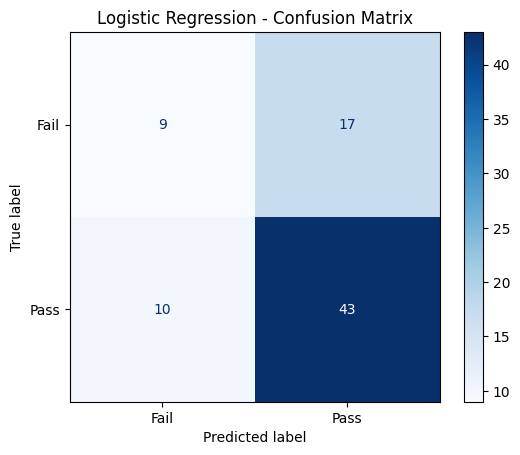

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [21]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline

decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

print("Decision Tree pipeline created successfully!")

Decision Tree pipeline created successfully!


## 5. Compare baseline model performance

In [22]:
# Train Decision Tree pipeline

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [23]:
# Make predictions

dt_predictions = decision_tree_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nDecision Tree Predictions:")
print(dt_predictions)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

Decision Tree Predictions:
['No' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'No' 'No' 'Yes' 'Yes'
 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes'
 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes'
 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Ye

In [24]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Accuracy (%):", dt_accuracy * 100)

Decision Tree Accuracy: 0.6075949367088608
Decision Tree Accuracy (%): 60.75949367088608


In [25]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [26]:
# Train Random Forest

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 6. Cross-validation

In [27]:
# Make Random Forest predictions

rf_predictions = random_forest_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nRandom Forest Predictions:")
print(rf_predictions)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

Random Forest Predictions:
['Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No'
 'Yes' 'No' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 

In [28]:
# Calculate Random Forest accuracy

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy (%):", rf_accuracy * 100)

Random Forest Accuracy: 0.6582278481012658
Random Forest Accuracy (%): 65.82278481012658


In [29]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline

knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

print("KNN pipeline created successfully!")


KNN pipeline created successfully!


In [30]:
# Train KNN model

knn_pipeline.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [31]:
# Make KNN predictions

knn_predictions = knn_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nKNN Predictions:")
print(knn_predictions)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

KNN Predictions:
['Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No'
 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No'
 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 

C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\PMLS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs

In [32]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", knn_accuracy)
print("KNN Accuracy (%):", knn_accuracy * 100)

KNN Accuracy: 0.5822784810126582
KNN Accuracy (%): 58.22784810126582


In [33]:
from sklearn.svm import SVC

svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(kernel="rbf"))
])

print("SVM pipeline created successfully!")

SVM pipeline created successfully!


In [34]:
# Train SVM model
svm_pipeline.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [35]:
# Make SVM predictions

svm_predictions = svm_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nSVM Predictions:")
print(svm_predictions)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

SVM Predictions:
['Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' '

In [36]:
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", svm_accuracy)
print("SVM Accuracy (%):", svm_accuracy * 100)

SVM Accuracy: 0.6835443037974683
SVM Accuracy (%): 68.35443037974683


In [37]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM"
    ],
    "Accuracy": [
        accuracy,
        dt_accuracy,
        rf_accuracy,
        knn_accuracy,
        svm_accuracy
    ]
})

model_results = model_results.sort_values(
    by="Accuracy",
    ascending=False
)

print(model_results)

                 Model  Accuracy
4                  SVM  0.683544
0  Logistic Regression  0.658228
2        Random Forest  0.658228
1        Decision Tree  0.607595
3                  KNN  0.582278


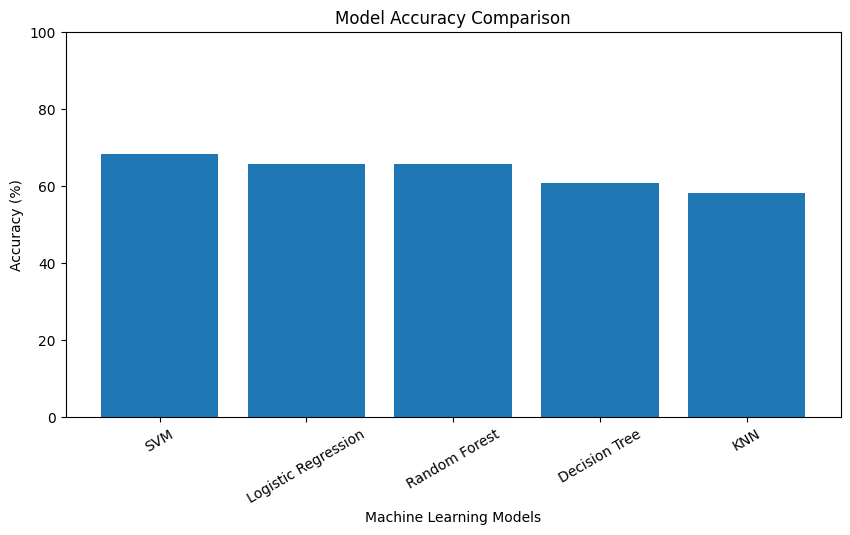

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    model_results["Model"],
    model_results["Accuracy"] * 100
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

In [39]:
from sklearn.metrics import classification_report

print("SVM Classification Report:")
print(classification_report(y_test, svm_predictions))

SVM Classification Report:
              precision    recall  f1-score   support

          No       0.55      0.23      0.32        26
         Yes       0.71      0.91      0.79        53

    accuracy                           0.68        79
   macro avg       0.63      0.57      0.56        79
weighted avg       0.65      0.68      0.64        79



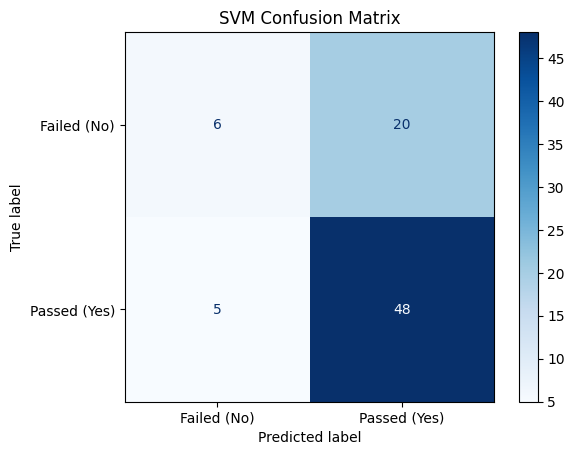

Confusion Matrix:
[[ 6 20]
 [ 5 48]]


In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_svm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Failed (No)", "Passed (Yes)"]
)

disp.plot(cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm_svm)

In [41]:
# Logistic Regression with balanced class weights

balanced_logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

print("Balanced Logistic Regression pipeline created!")

Balanced Logistic Regression pipeline created!


In [42]:
# Train balanced Logistic Regression

balanced_logistic_pipeline.fit(X_train, y_train)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [43]:
balanced_logistic_predictions = balanced_logistic_pipeline.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nBalanced Logistic Regression Predictions:")
print(balanced_logistic_predictions)

Actual Values:
<ArrowStringArray>
['Yes',  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes', 'Yes',
  'No', 'Yes', 'Yes',  'No', 'Yes',  'No',  'No',  'No',  'No', 'Yes', 'Yes',
  'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes', 'Yes',
 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',  'No', 'Yes',
  'No',  'No',  'No', 'Yes', 'Yes', 'Yes',  'No',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes',  'No', 'Yes',  'No', 'Yes', 'Yes',  'No', 'Yes', 'Yes',  'No',
 'Yes', 'Yes']
Length: 79, dtype: str

Balanced Logistic Regression Predictions:
['No' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes'
 'No' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes'
 'No' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'No'

In [44]:
print("Balanced Logistic Regression Report:")
print(
    classification_report(
        y_test,
        balanced_logistic_predictions
    )
)

Balanced Logistic Regression Report:
              precision    recall  f1-score   support

          No       0.40      0.46      0.43        26
         Yes       0.71      0.66      0.69        53

    accuracy                           0.59        79
   macro avg       0.56      0.56      0.56        79
weighted avg       0.61      0.59      0.60        79



In [45]:
balanced_cm = confusion_matrix(
    y_test,
    balanced_logistic_predictions,
    labels=["No", "Yes"]
)

print("Balanced Logistic Regression Confusion Matrix:")
print(balanced_cm)


Balanced Logistic Regression Confusion Matrix:
[[12 14]
 [18 35]]


In [46]:
balanced_rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

print("Balanced Random Forest pipeline created!")

Balanced Random Forest pipeline created!


In [47]:
balanced_rf_pipeline.fit(X_train, y_train)

print("Balanced Random Forest trained successfully!")

Balanced Random Forest trained successfully!


In [48]:
balanced_rf_predictions = balanced_rf_pipeline.predict(X_test)

print("Balanced Random Forest Predictions:")
print(balanced_rf_predictions)

Balanced Random Forest Predictions:
['Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes'
 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes']


In [49]:
print("Balanced Random Forest Classification Report:")
print(
    classification_report(
        y_test,
        balanced_rf_predictions
    )
)

Balanced Random Forest Classification Report:
              precision    recall  f1-score   support

          No       0.62      0.19      0.29        26
         Yes       0.70      0.94      0.81        53

    accuracy                           0.70        79
   macro avg       0.66      0.57      0.55        79
weighted avg       0.68      0.70      0.64        79



In [50]:
balanced_rf_cm = confusion_matrix(
    y_test,
    balanced_rf_predictions,
    labels=["No", "Yes"]
)

print("Balanced Random Forest Confusion Matrix:")
print(balanced_rf_cm)

Balanced Random Forest Confusion Matrix:
[[ 5 21]
 [ 3 50]]


In [51]:
balanced_rf_accuracy = accuracy_score(
    y_test,
    balanced_rf_predictions
)

print("Balanced Random Forest Accuracy:", balanced_rf_accuracy)
print("Accuracy (%):", balanced_rf_accuracy * 100)

Balanced Random Forest Accuracy: 0.6962025316455697
Accuracy (%): 69.62025316455697


In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (logistic_pipeline, y_pred),
    "Decision Tree": (decision_tree_pipeline, dt_predictions),
    "Random Forest": (random_forest_pipeline, rf_predictions),
    "KNN": (knn_pipeline, knn_predictions),
    "SVM": (svm_pipeline, svm_predictions),
    "Balanced Logistic Regression": (
        balanced_logistic_pipeline,
        balanced_logistic_predictions
    ),
    "Balanced Random Forest": (
        balanced_rf_pipeline,
        balanced_rf_predictions
    )
}

results = []

for model_name, (model, predictions) in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Fail Precision": precision_score(
            y_test, predictions, pos_label="No", zero_division=0
        ),
        "Fail Recall": recall_score(
            y_test, predictions, pos_label="No", zero_division=0
        ),
        "Fail F1": f1_score(
            y_test, predictions, pos_label="No", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Fail Recall",
    ascending=False
)

print(comparison_df.round(3))

                          Model  Accuracy  Fail Precision  Fail Recall  \
1                 Decision Tree     0.608           0.419        0.500   
5  Balanced Logistic Regression     0.595           0.400        0.462   
0           Logistic Regression     0.658           0.474        0.346   
2                 Random Forest     0.658           0.462        0.231   
4                           SVM     0.684           0.545        0.231   
3                           KNN     0.582           0.294        0.192   
6        Balanced Random Forest     0.696           0.625        0.192   

   Fail F1  
1    0.456  
5    0.429  
0    0.400  
2    0.308  
4    0.324  
3    0.233  
6    0.294  


## 7. Class imbalance experiments

In [53]:
from sklearn.model_selection import StratifiedKFold, cross_validate

print("Cross-validation tools imported successfully!")

Cross-validation tools imported successfully!


In [54]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation created!")

5-Fold Stratified Cross-Validation created!


In [55]:
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

scoring = {
    "accuracy": "accuracy",
    "fail_precision": make_scorer(
        precision_score,
        pos_label="No",
        zero_division=0
    ),
    "fail_recall": make_scorer(
        recall_score,
        pos_label="No",
        zero_division=0
    ),
    "fail_f1": make_scorer(
        f1_score,
        pos_label="No",
        zero_division=0
    )
}

print("Evaluation metrics configured successfully!")

Evaluation metrics configured successfully!


In [56]:
dt_cv_results = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Decision Tree Cross-Validation Results:")
print("Accuracy:", dt_cv_results["test_accuracy"])
print("Fail Recall:", dt_cv_results["test_fail_recall"])
print("Fail F1:", dt_cv_results["test_fail_f1"])


Decision Tree Cross-Validation Results:
Accuracy: [0.609375   0.71428571 0.68253968 0.71428571 0.61904762]
Fail Recall: [0.42857143 0.52380952 0.52380952 0.57142857 0.3       ]
Fail F1: [0.41860465 0.55       0.52380952 0.57142857 0.33333333]


In [57]:
print("Decision Tree Average Cross-Validation Scores")

print(
    "Mean Accuracy:",
    dt_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    dt_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    dt_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    dt_cv_results["test_accuracy"].std()
)


Decision Tree Average Cross-Validation Scores
Mean Accuracy: 0.6679067460317462
Mean Fail Recall: 0.46952380952380945
Mean Fail F1: 0.4794352159468439
Standard Deviation (Accuracy): 0.04545177621749529


In [58]:
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression Cross-Validation Results:")
print("Accuracy:", logistic_cv_results["test_accuracy"])
print("Fail Recall:", logistic_cv_results["test_fail_recall"])
print("Fail F1:", logistic_cv_results["test_fail_f1"])


Logistic Regression Cross-Validation Results:
Accuracy: [0.609375   0.73015873 0.6984127  0.66666667 0.71428571]
Fail Recall: [0.14285714 0.57142857 0.42857143 0.33333333 0.4       ]
Fail F1: [0.19354839 0.58536585 0.48648649 0.4        0.47058824]


In [59]:
print("Logistic Regression Average CV Scores")

print(
    "Mean Accuracy:",
    logistic_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    logistic_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    logistic_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    logistic_cv_results["test_accuracy"].std()
)

Logistic Regression Average CV Scores
Mean Accuracy: 0.683779761904762
Mean Fail Recall: 0.37523809523809526
Mean Fail F1: 0.4271977925071829
Standard Deviation (Accuracy): 0.042719249245625215


In [60]:
rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Random Forest Cross-Validation Results:")
print("Accuracy:", rf_cv_results["test_accuracy"])
print("Fail Recall:", rf_cv_results["test_fail_recall"])
print("Fail F1:", rf_cv_results["test_fail_f1"])

Random Forest Cross-Validation Results:
Accuracy: [0.65625    0.66666667 0.66666667 0.73015873 0.66666667]
Fail Recall: [0.14285714 0.28571429 0.23809524 0.38095238 0.15      ]
Fail F1: [0.21428571 0.36363636 0.32258065 0.48484848 0.22222222]


In [61]:
print("Random Forest Average CV Scores")

print(
    "Mean Accuracy:",
    rf_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    rf_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    rf_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    rf_cv_results["test_accuracy"].std()
)

Random Forest Average CV Scores
Mean Accuracy: 0.677281746031746
Mean Fail Recall: 0.23952380952380947
Mean Fail F1: 0.32151468603081507
Standard Deviation (Accuracy): 0.02674453036151503


In [62]:
knn_cv_results = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("KNN Cross-Validation Results:")
print("Accuracy:", knn_cv_results["test_accuracy"])
print("Fail Recall:", knn_cv_results["test_fail_recall"])
print("Fail F1:", knn_cv_results["test_fail_f1"])

KNN Cross-Validation Results:
Accuracy: [0.671875   0.66666667 0.68253968 0.66666667 0.73015873]
Fail Recall: [0.28571429 0.23809524 0.19047619 0.23809524 0.3       ]
Fail F1: [0.36363636 0.32258065 0.28571429 0.32258065 0.4137931 ]


In [63]:
print("KNN Average CV Scores")

print(
    "Mean Accuracy:",
    knn_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    knn_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    knn_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    knn_cv_results["test_accuracy"].std()
)

KNN Average CV Scores
Mean Accuracy: 0.6835813492063492
Mean Fail Recall: 0.25047619047619046
Mean Fail F1: 0.34166100862430115
Standard Deviation (Accuracy): 0.0239991211022618


In [64]:
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("SVM Cross-Validation Results:")
print("Accuracy:", svm_cv_results["test_accuracy"])
print("Fail Recall:", svm_cv_results["test_fail_recall"])
print("Fail F1:", svm_cv_results["test_fail_f1"])

SVM Cross-Validation Results:
Accuracy: [0.71875    0.6984127  0.63492063 0.74603175 0.76190476]
Fail Recall: [0.19047619 0.33333333 0.0952381  0.28571429 0.3       ]
Fail F1: [0.30769231 0.42424242 0.14814815 0.42857143 0.44444444]


In [65]:
print("SVM Average CV Scores")

print(
    "Mean Accuracy:",
    svm_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    svm_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    svm_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    svm_cv_results["test_accuracy"].std()
)

SVM Average CV Scores
Mean Accuracy: 0.7120039682539682
Mean Fail Recall: 0.24095238095238095
Mean Fail F1: 0.35061975061975065
Standard Deviation (Accuracy): 0.04431715402745843


In [66]:
balanced_logistic_cv_results = cross_validate(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Balanced Logistic Regression Cross-Validation Results:")
print("Accuracy:", balanced_logistic_cv_results["test_accuracy"])
print("Fail Recall:", balanced_logistic_cv_results["test_fail_recall"])
print("Fail F1:", balanced_logistic_cv_results["test_fail_f1"])

Balanced Logistic Regression Cross-Validation Results:
Accuracy: [0.609375   0.71428571 0.6984127  0.6984127  0.6984127 ]
Fail Recall: [0.38095238 0.76190476 0.61904762 0.57142857 0.65      ]
Fail F1: [0.3902439  0.64       0.57777778 0.55813953 0.57777778]


In [67]:
print("Balanced Logistic Regression Average CV Scores")

print(
    "Mean Accuracy:",
    balanced_logistic_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    balanced_logistic_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    balanced_logistic_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    balanced_logistic_cv_results["test_accuracy"].std()
)


Balanced Logistic Regression Average CV Scores
Mean Accuracy: 0.6837797619047621
Mean Fail Recall: 0.5966666666666666
Mean Fail F1: 0.5487877985756601
Standard Deviation (Accuracy): 0.03770689649734951


In [68]:
balanced_rf_cv_results = cross_validate(
    balanced_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Balanced Random Forest Cross-Validation Results:")
print("Accuracy:", balanced_rf_cv_results["test_accuracy"])
print("Fail Recall:", balanced_rf_cv_results["test_fail_recall"])
print("Fail F1:", balanced_rf_cv_results["test_fail_f1"])

Balanced Random Forest Cross-Validation Results:
Accuracy: [0.671875   0.71428571 0.71428571 0.73015873 0.74603175]
Fail Recall: [0.14285714 0.28571429 0.33333333 0.23809524 0.3       ]
Fail F1: [0.22222222 0.4        0.4375     0.37037037 0.42857143]


In [69]:
print("Balanced Random Forest Average CV Scores")

print(
    "Mean Accuracy:",
    balanced_rf_cv_results["test_accuracy"].mean()
)

print(
    "Mean Fail Recall:",
    balanced_rf_cv_results["test_fail_recall"].mean()
)

print(
    "Mean Fail F1:",
    balanced_rf_cv_results["test_fail_f1"].mean()
)

print(
    "Standard Deviation (Accuracy):",
    balanced_rf_cv_results["test_accuracy"].std()
)

Balanced Random Forest Average CV Scores
Mean Accuracy: 0.715327380952381
Mean Fail Recall: 0.26
Mean Fail F1: 0.3717328042328042
Standard Deviation (Accuracy): 0.02471034804905563


In [70]:
cv_models = {
    "Decision Tree": dt_cv_results,
    "Logistic Regression": logistic_cv_results,
    "Random Forest": rf_cv_results,
    "KNN": knn_cv_results,
    "SVM": svm_cv_results,
    "Balanced Logistic Regression": balanced_logistic_cv_results,
    "Balanced Random Forest": balanced_rf_cv_results
}

cv_comparison = []

for model_name, results in cv_models.items():

    cv_comparison.append({
        "Model": model_name,
        "Mean Accuracy": results["test_accuracy"].mean(),
        "Mean Fail Recall": results["test_fail_recall"].mean(),
        "Mean Fail F1": results["test_fail_f1"].mean(),
        "Accuracy Std": results["test_accuracy"].std()
    })

cv_comparison_df = pd.DataFrame(cv_comparison)

cv_comparison_df = cv_comparison_df.sort_values(
    by="Mean Fail F1",
    ascending=False
)

print("Complete Cross-Validation Model Comparison")
cv_comparison_df.round(3)

Complete Cross-Validation Model Comparison


,Model,Mean Accuracy,Mean Fail Recall,Mean Fail F1,Accuracy Std
5,Balanced Logistic Regression,0.684,0.597,0.549,0.038
0,Decision Tree,0.668,0.470,0.479,0.045
1,Logistic Regression,0.684,0.375,0.427,0.043
6,Balanced Random Forest,0.715,0.260,0.372,0.025
4,SVM,0.712,0.241,0.351,0.044
3,KNN,0.684,0.250,0.342,0.024
2,Random Forest,0.677,0.240,0.322,0.027


In [71]:
from sklearn.metrics import make_scorer, f1_score

fail_f1_scorer = make_scorer(
    f1_score,
    pos_label="No",
    zero_division=0
)

print("Fail F1 scorer created successfully!")
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

print(param_grid)

Fail F1 scorer created successfully!
{'model__C': [0.01, 0.1, 1, 10, 100]}


## 8. Cross-validation comparison and hyperparameter tuning

In [72]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(
    estimator=balanced_logistic_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=fail_f1_scorer,
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Fail F1:", grid_search.best_score_)

Best Parameters: {'model__C': 10}
Best Cross-Validation Fail F1: 0.5538217604046402


In [73]:
best_model = grid_search.best_estimator_

print("Best Model:", best_model)
print("\nBest Parameters:", grid_search.best_params_)
print("Best CV Fail F1:", grid_search.best_score_)


Best Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'Medu', 'Fedu',
                                                   'traveltime', 'studytime',
                                                   'failures', 'famrel',
                                                   'freetime', 'goout', 'Dalc',
                                                   'Walc', 'health',
                                                   'absences']),
                                                 ('cat',
                                                  Pipelin

In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Make predictions using the tuned model
tuned_predictions = best_model.predict(X_test)

# Calculate metrics
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

tuned_fail_precision = precision_score(
    y_test,
    tuned_predictions,
    pos_label="No",
    zero_division=0
)

tuned_fail_recall = recall_score(
    y_test,
    tuned_predictions,
    pos_label="No",
    zero_division=0
)

tuned_fail_f1 = f1_score(
    y_test,
    tuned_predictions,
    pos_label="No",
    zero_division=0
)

print("Tuned Model Test Results")
print("------------------------")
print(f"Accuracy: {tuned_accuracy:.3f}")
print(f"Fail Precision: {tuned_fail_precision:.3f}")
print(f"Fail Recall: {tuned_fail_recall:.3f}")
print(f"Fail F1: {tuned_fail_f1:.3f}")

Tuned Model Test Results
------------------------
Accuracy: 0.582
Fail Precision: 0.387
Fail Recall: 0.462
Fail F1: 0.421


In [75]:
final_model_summary = pd.DataFrame([
    {
        "Model": "Balanced Logistic Regression",
        "CV Fail F1": grid_search.best_score_,
        "Best C": grid_search.best_params_["model__C"],
        "Test Accuracy": tuned_accuracy,
        "Test Fail Recall": tuned_fail_recall,
        "Test Fail F1": tuned_fail_f1
    }
])

final_model_summary.round(3)

,Model,CV Fail F1,Best C,Test Accuracy,Test Fail Recall,Test Fail F1
0,Balanced Logistic Regression,0.554,10,0.582,0.462,0.421


In [76]:
from pathlib import Path

project_path = Path("..").resolve()

print("Project Directory:", project_path)
print("\nFiles and Folders:")

for item in sorted(project_path.iterdir()):
    print(item.name)

Project Directory: C:\Users\PMLS\Documents\Coding\System-7-Internship\AutoML-Studio

Files and Folders:
app.py
modules
notebooks
requirements.txt
sample_data


## 9. Tune and evaluate the selected model

In [77]:
modules_path = project_path / "modules"

print("Modules Folder:")
for item in sorted(modules_path.iterdir()):
    print(item.name)

Modules Folder:
__pycache__
data_loader.py
eda.py
evaluation.py
model_training.py
pdf_report.py
preprocessing.py
task_detection.py


In [83]:

import importlib
from pathlib import Path

import modules.data_loader as data_loader

# Reload the updated module
importlib.reload(data_loader)

# Define the dataset path
sample_path = project_root / "sample_data" / "student-mat.csv"

# Check that the dataset exists
if not sample_path.exists():
    raise FileNotFoundError(f"Dataset not found: {sample_path}")

# Load the dataset
df_test = data_loader.load_csv(sample_path)

print("Dataset Shape:", df_test.shape)
print("Columns:", df_test.columns.tolist())
print("\nDataset loaded successfully!")


Dataset Shape: (395, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset loaded successfully!


In [84]:
is_valid = data_loader.validate_dataset(df_test)

print("Dataset Valid:", is_valid)

Dataset Valid: True


In [85]:
import sys
from pathlib import Path

# Add project directory to Python path
project_path = Path.cwd().parent
sys.path.append(str(project_path))

# Import our module
from modules.data_loader import load_csv, validate_dataset

# Load sample dataset
sample_path = project_path / "sample_data" / "student-mat.csv"

df_test = load_csv(sample_path)

# Validate dataset
is_valid = validate_dataset(df_test)

print("Dataset loaded successfully!")
print("Dataset Shape:", df_test.shape)
print("Dataset Valid:", is_valid)

print("\nFirst 5 Rows:")
print(df_test.head())

Dataset loaded successfully!
Dataset Shape: (395, 33)
Dataset Valid: True

First 5 Rows:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

In [86]:
import importlib
import modules.eda as eda

# Reload the module
importlib.reload(eda)

# 1. Dataset overview
overview = eda.get_dataset_overview(df_test)

print("DATASET OVERVIEW")
print("----------------")
for key, value in overview.items():
    print(f"{key}: {value}")


# 2. Column summary
print("\nCOLUMN SUMMARY")
print("--------------")
print(eda.get_column_summary(df_test).head(10))


# 3. Numeric statistics
print("\nNUMERIC STATISTICS")
print("------------------")
print(eda.get_numeric_statistics(df_test))


# 4. Categorical statistics
print("\nCATEGORICAL STATISTICS")
print("----------------------")

categorical_results = eda.get_categorical_statistics(df_test)

for column, frequencies in categorical_results.items():
    print(f"\n{column}:")
    print(frequencies)

DATASET OVERVIEW
----------------
Total Rows: 395
Total Columns: 33
Missing Values: 0
Duplicate Rows: 0
Memory Usage (KB): 122.62

COLUMN SUMMARY
--------------
        Data Type  Missing Values  Unique Values
school        str               0              2
sex           str               0              2
age         int64               0              8
address       str               0              2
famsize       str               0              2
Pstatus       str               0              2
Medu        int64               0              5
Fedu        int64               0              5
Mjob          str               0              5
Fjob          str               0              5

NUMERIC STATISTICS
------------------
            count       mean       std   min   25%   50%   75%   max
age         395.0  16.696203  1.276043  15.0  16.0  17.0  18.0  22.0
Medu        395.0   2.749367  1.094735   0.0   2.0   3.0   4.0   4.0
Fedu        395.0   2.521519  1.088201   0.0   2.0   2

## 10. Connect the notebook to reusable project modules

In [87]:
import importlib
import modules.preprocessing as preprocessing

importlib.reload(preprocessing)

# Create the Passed target
df_test["Passed"] = (df_test["G3"] >= 10).map({
    True: "Yes",
    False: "No"
})

# Separate features and target
X, y = preprocessing.separate_features_target(
    df_test,
    "Passed"
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (395, 33)
Target Shape: (395,)

Feature Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Target Distribution:
Passed
Yes    265
No     130
Name: count, dtype: int64


In [88]:
importlib.reload(preprocessing)

numeric_columns, categorical_columns = (
    preprocessing.identify_column_types(X)
)

print("Numeric Columns:")
print(numeric_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nTotal Numeric Columns:", len(numeric_columns))
print("Total Categorical Columns:", len(categorical_columns))

Numeric Columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Total Numeric Columns: 16
Total Categorical Columns: 17


In [89]:
importlib.reload(preprocessing)

# Build preprocessing pipeline
preprocessor = preprocessing.build_preprocessor(
    numeric_columns,
    categorical_columns
)

# Transform the dataset
X_processed = preprocessor.fit_transform(X)

print("Original Shape:", X.shape)
print("Processed Shape:", X_processed.shape)

print("\nPreprocessing completed successfully!")

Original Shape: (395, 33)
Processed Shape: (395, 59)

Preprocessing completed successfully!


In [90]:
import importlib
import modules.model_training as model_training

importlib.reload(model_training)

# Get classification models
models = model_training.get_classification_models()

print("Available Classification Models:")
print("-------------------------------")

for name, model in models.items():
    print(f"{name}: {type(model).__name__}")

print("\nTotal Models:", len(models))

Available Classification Models:
-------------------------------
Logistic Regression: LogisticRegression
Decision Tree: DecisionTreeClassifier
Random Forest: RandomForestClassifier
Gradient Boosting: GradientBoostingClassifier
Support Vector Machine: SVC
K-Nearest Neighbors: KNeighborsClassifier

Total Models: 6


In [91]:
importlib.reload(preprocessing)
importlib.reload(model_training)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify column types
numeric_columns, categorical_columns = (
    preprocessing.identify_column_types(X_train)
)

# Build preprocessing pipeline
preprocessor = preprocessing.build_preprocessor(
    numeric_columns,
    categorical_columns
)

# Get Logistic Regression
models = model_training.get_classification_models()
logistic_model = models["Logistic Regression"]

# Combine preprocessing and model
full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", logistic_model)
])

# Train
trained_model = model_training.train_model(
    full_pipeline,
    X_train,
    y_train
)

print("Model Training Successful!")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Trained Model:", trained_model)

Model Training Successful!
Training Samples: 316
Testing Samples: 79
Trained Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'Medu', 'Fedu',
                                                   'traveltime', 'studytime',
                                                   'failures', 'famrel',
                                                   'freetime', 'goout', 'Dalc',
                                                   'Walc', 'health', 'absences',
                                                   'G1', 'G2', 'G3']),
                    

In [92]:
importlib.reload(model_training)

# Generate predictions on test data
predictions = model_training.predict_model(
    trained_model,
    X_test
)

print("Actual Values:")
print(y_test.head(10).tolist())

print("\nPredicted Values:")
print(predictions[:10])

print("\nTotal Predictions:", len(predictions))

Actual Values:
['Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes']

Predicted Values:
['Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes']

Total Predictions: 79


In [93]:
importlib.reload(model_training)

# Generate prediction probabilities
probabilities = model_training.predict_probabilities(
    trained_model,
    X_test
)

# Get class labels
class_labels = trained_model.classes_

print("Class Labels:", class_labels)

print("\nPrediction Probabilities (First 5 Students):")

for i in range(5):
    print(f"\nStudent {i + 1}:")
    for label, probability in zip(class_labels, probabilities[i]):
        print(f"{label}: {probability * 100:.2f}%")

Class Labels: ['No' 'Yes']

Prediction Probabilities (First 5 Students):

Student 1:
No: 0.95%
Yes: 99.05%

Student 2:
No: 96.89%
Yes: 3.11%

Student 3:
No: 0.62%
Yes: 99.38%

Student 4:
No: 1.61%
Yes: 98.39%

Student 5:
No: 0.00%
Yes: 100.00%


In [94]:
import importlib
import modules.evaluation as evaluation

importlib.reload(evaluation)

# Evaluate Logistic Regression
metrics = evaluation.evaluate_model(
    trained_model,
    X_test,
    y_test
)

print("MODEL EVALUATION")
print("----------------")

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")


# Detailed classification report
print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    evaluation.get_classification_report(
        trained_model,
        X_test,
        y_test
    )
)

MODEL EVALUATION
----------------
Accuracy: 0.8861
Precision: 0.8917
Recall: 0.8861
F1 Score: 0.8875

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

          No       0.79      0.88      0.84        26
         Yes       0.94      0.89      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.89      0.87        79
weighted avg       0.89      0.89      0.89        79

